# Week 11B: Make a smooth DSM from LiDAR

We will use two Philadelphia LAS files, create a digital surface model with PDAL, and smooth isolated bright pixels.

A **DSM** includes roofs, trees, and ground. Elevations are relative to a vertical datum; they are not building heights above ground.

<a href="lecture-11B.ipynb" download>Download notebook</a> · [Previous lesson: large-data visualization](lecture-11A.html)


## Before you start

Use **Python (largeviz)** for both lessons. Download <a href="environment-viz.yml" download>environment-viz.yml</a> beside the notebooks. In a terminal opened in this lab folder:

```bash
# First time only:
conda env create -f environment-viz.yml
# If largeviz already exists, update it instead:
# conda env update -n largeviz -f environment-viz.yml
conda activate largeviz
python -m ipykernel install --user --name largeviz --display-name "Python (largeviz)"
jupyter lab
```

In VS Code, open the notebook and select **Python (largeviz)**. Run the cells from top to bottom. See the [README](README.md) for setup troubleshooting.


## Download and save the LiDAR files

1. Create a folder named `week11` on your computer (or use the folder from Lecture 11A). Save <a href="lecture-11B.ipynb" download>lecture-11B.ipynb</a> and <a href="environment-viz.yml" download>environment-viz.yml</a> in it.
2. Inside `week11`, create a `data` folder, then a `lidar` folder inside it.
3. Download **both** LAS files using the direct links below. Save them in `data/lidar/` and keep their original filenames. If clicking a link does not download it, right-click and choose **Save Link As…**.

| Case study | Direct download | Size |
| --- | --- | --- |
| University City | [Download Philadelphia_394.las](https://www.pasda.psu.edu/download/phillyLiDAR/2022/LAS/Classified_LAS/Philadelphia_394.las) | about 1.09 GB |
| Center City | [Download Philadelphia_456.las](https://www.pasda.psu.edu/download/phillyLiDAR/2022/LAS/Classified_LAS/Philadelphia_456.las) | about 997 MB |

Wait for both downloads to finish before running the notebook. These are `.las` files; **no extraction is needed**. Allow at least 3 GB of free space for the data and results.

```text
week11/
├── lecture-11B.ipynb
├── environment-viz.yml
└── data/
    └── lidar/
        ├── Philadelphia_394.las
        └── Philadelphia_456.las
```

Open the notebook from this folder and select **Python (largeviz)**. All paths below are relative to the notebook's folder. If you saved the LAS files somewhere else, edit the two paths in Step 2.

## 1. Import packages and set the output folder


In [1]:
from pathlib import Path
import json
import math

import pdal
import rasterio
from rasterio.plot import show
from pyproj import CRS
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

OUT = Path("outputs/lidar/case_studies")
OUT.mkdir(parents=True, exist_ok=True)
print("PDAL:", pdal.__version__)


PDAL: 3.5.3


## 2. Open your downloaded files

These PASDA tiles cover approximately 914 × 914 m each. They are case studies, not complete neighborhood coverage. The bounds below select the corresponding footprints in the source coordinate system.


In [2]:
cases = [
    {"zone": "University City", "name": "Philadelphia_394.las",
     "bounds": [2685000, 235000, 2688000, 238000]},
    {"zone": "Center City", "name": "Philadelphia_456.las",
     "bounds": [2691000, 235000, 2694000, 238000]},
]
pd.DataFrame(cases)[["zone", "name"]]

,zone,name
0,University City,Philadelphia_394.las
1,Center City,Philadelphia_456.las


Set the paths to the files you downloaded. If you see `FileNotFoundError` in the next step, check that the files are in `data/lidar/` beside this notebook and that their names match exactly.


In [3]:
las_paths = [
    Path("data/lidar/Philadelphia_394.las"),
    Path("data/lidar/Philadelphia_456.las"),
]


## 3. Check the coordinate system and units

Read the LAS header with `quickinfo`. Keep the native horizontal CRS and convert Z to meters using its vertical CRS. Convert the **1 m** pixel size to the horizontal coordinate units too. This changes units, not the vertical datum.


In [4]:
infos = []
for path in las_paths:
    reader = pdal.Pipeline(json.dumps([{"type": "readers.las", "filename": str(path)}]))
    header = reader.quickinfo["readers.las"]
    crs = CRS.from_wkt(header["metadata"]["srs"]["compoundwkt"])
    if not crs.is_compound:
        raise ValueError("Expected a horizontal + vertical CRS; inspect the LAS metadata.")
    horizontal, vertical = crs.sub_crs_list[:2]
    if horizontal.is_bound:
        horizontal = horizontal.source_crs
    if not horizontal.is_projected:
        raise ValueError("Expected projected XY coordinates.")
    infos.append({"points": header["num_points"],
                  "horizontal": horizontal, "vertical": vertical,
                  "xy_to_m": horizontal.axis_info[0].unit_conversion_factor,
                  "z_to_m": vertical.axis_info[0].unit_conversion_factor})

pd.DataFrame([{"zone": case["zone"], "points": info["points"],
               "horizontal_crs": info["horizontal"].name,
               "xy_units": info["horizontal"].axis_info[0].unit_name,
               "vertical_crs": info["vertical"].name,
               "z_units": info["vertical"].axis_info[0].unit_name}
              for case, info in zip(cases, infos)])

,zone,points,horizontal_crs,xy_units,vertical_crs,z_units
0,University City,36291327,NAD83(2011) / Pennsylvania South (ftUS),US Survey Foot,NAVD88 height (ftUS) - US Geoid Model of 2018,US Survey Foot
1,Center City,33187641,NAD83(2011) / Pennsylvania South (ftUS),US Survey Foot,NAVD88 height (ftUS) - US Geoid Model of 2018,US Survey Foot


## 4. Create raw DSM rasters

Keep first returns and exclude classified noise and withheld points. Compare two ways to rasterize the same points:

- **Maximum:** the highest return in each pixel; sensitive to individual high points.
- **IDW:** a distance-weighted average within **1.5 m** of each cell center; a smoother estimated surface.

A small radius limits mixing across roofs and streets. No extra gap filling is applied. See [PDAL's GDAL writer](https://pdal.io/en/stable/stages/writers.gdal.html).


In [5]:
CELL_SIZE_M = 1.0
NODATA = -9999.0

def make_dsm_pipeline(path, case, info, destination, method="idw"):
    resolution = CELL_SIZE_M / info["xy_to_m"]
    left, bottom, right, top = case["bounds"]
    origin_x = math.floor(left / resolution) * resolution
    origin_y = math.floor(bottom / resolution) * resolution
    return {"pipeline": [
        {"type": "readers.las", "filename": str(path)},
        {"type": "filters.crop", "bounds": f"([{left},{right}],[{bottom},{top}])"},
        {"type": "filters.expression", "expression":
         "ReturnNumber == 1 && Classification != 7 && Classification != 18 && Withheld == 0"},
        {"type": "filters.assign", "value": f"Z = Z * {info['z_to_m']:.15g}"},
        {"type": "writers.gdal", "filename": str(destination),
         "resolution": resolution, "origin_x": origin_x, "origin_y": origin_y,
         "width": math.floor((right-origin_x)/resolution) + 1,
         "height": math.floor((top-origin_y)/resolution) + 1,
         "output_type": method, "binmode": method == "max",
         "radius": 1.5 * resolution, "window_size": 0,
         "data_type": "float32", "nodata": NODATA,
         "override_srs": info["horizontal"].to_wkt(),
         "gdalopts": "COMPRESS=DEFLATE,TILED=YES"},
    ]}



In [6]:
raw_paths = []
max_paths = []
for path, case, info in zip(las_paths, cases, infos):
    for method in ["max", "idw"]:
        destination = OUT / f"{path.stem}_{method}.tif"
        specification = make_dsm_pipeline(path, case, info, destination, method)
        destination.with_suffix(".json").write_text(json.dumps(specification, indent=2))
        pipeline = pdal.Pipeline(json.dumps(specification))
        pipeline.execute_streaming(chunk_size=250_000)
        with rasterio.open(destination, "r+") as dst:
            dst.set_band_unit(1, "m")
            dst.update_tags(vertical_reference=info["vertical"].name, method=method)
        (max_paths if method == "max" else raw_paths).append(destination)
        print(case["zone"], method, "→", destination.name)


University City max → Philadelphia_394_max.tif


University City idw → Philadelphia_394_idw.tif


Center City max → Philadelphia_456_max.tif


Center City idw → Philadelphia_456_idw.tif


## 5. Remove isolated pixels with a median filter

A **3 × 3 median** replaces each pixel with its neighborhood median. It reduces speckle while retaining broad roof edges better than a blur. It can remove small roof features and canopy peaks, so keep both raw rasters for analysis.

Temporarily use nearest valid values so NoData cannot contaminate the filter, then restore the exact IDW NoData mask. We leave remaining gaps and water unfilled.


In [7]:
from scipy.ndimage import distance_transform_edt, median_filter

dsm_paths = []
for path in raw_paths:
    with rasterio.open(path) as src:
        data = src.read(1, masked=True)
        valid = ~np.ma.getmaskarray(data)
        nearest = distance_transform_edt(~valid, return_distances=False, return_indices=True)
        smooth = median_filter(data.data[tuple(nearest)], size=3, mode="nearest")
        smooth[~valid] = src.nodata
        profile = src.profile.copy()
        tags = src.tags()
    destination = path.with_name(path.stem.replace("_idw", "_dsm") + ".tif")
    with rasterio.open(destination, "w", **profile) as dst:
        dst.write(smooth.astype("float32"), 1)
        dst.set_band_unit(1, "m")
        dst.update_tags(**tags, smoothing="3x3 median; IDW NoData mask retained")
    destination.with_suffix(".json").write_text(json.dumps({
        "source_raster": path.name, "source_pipeline": path.with_suffix(".json").name,
        "smoothing": "3x3 median", "preserve_nodata": True
    }, indent=2))
    dsm_paths.append(destination)
    print(destination.name)


Philadelphia_394_dsm.tif
Philadelphia_456_dsm.tif


## 6. Compare before and after

The same central 250 × 250 pixel window and color scale show maximum, IDW, and smoothed IDW for each tile. The GeoTIFFs keep elevation values in meters; color limits affect only the plots.


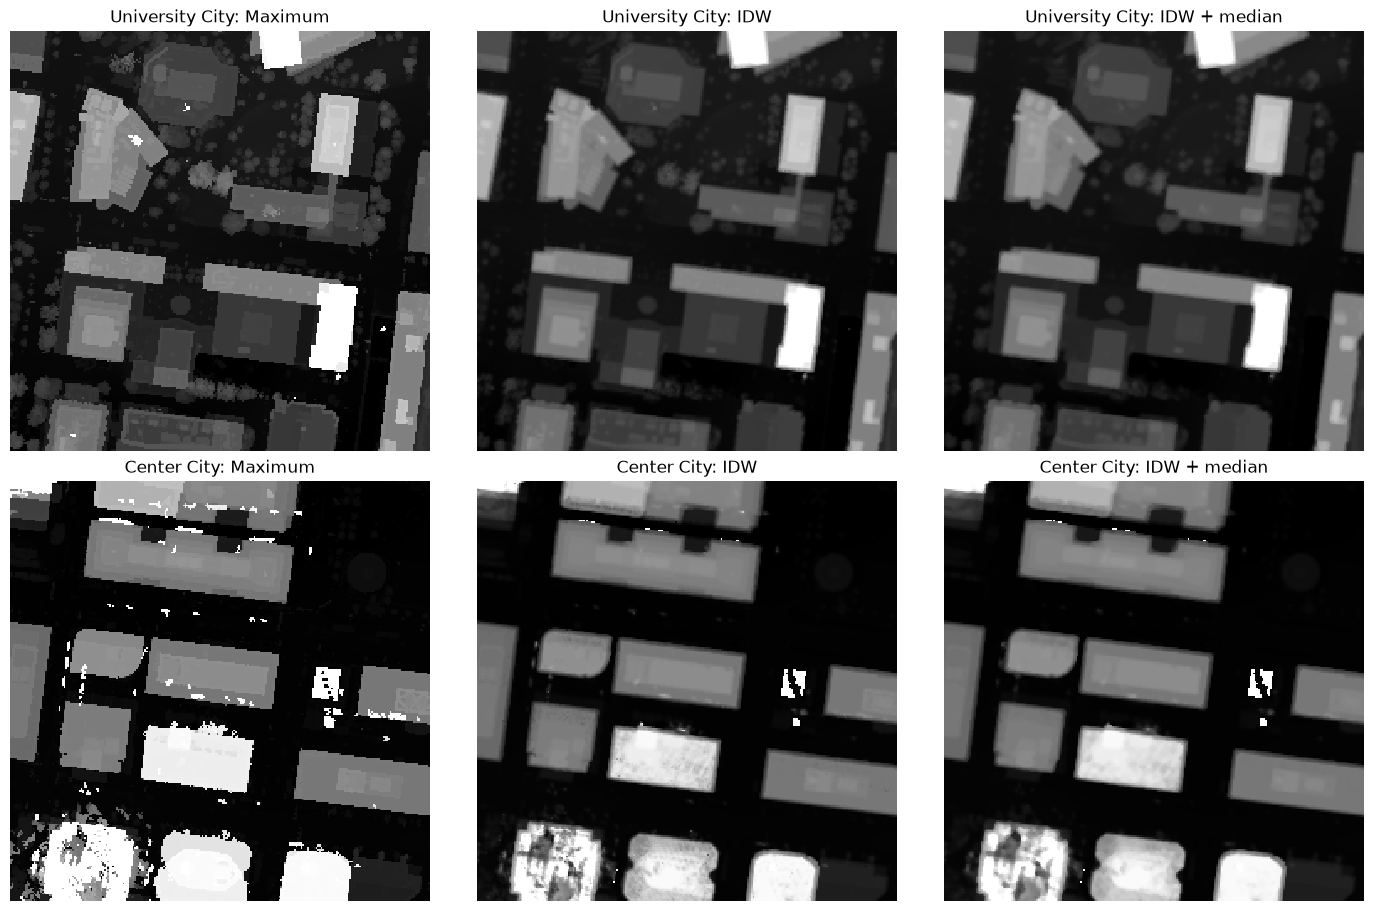

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(14, 9), constrained_layout=True)
for row, (case, paths) in enumerate(zip(cases, zip(max_paths, raw_paths, dsm_paths))):
    windows = []
    for path in paths:
        with rasterio.open(path) as src:
            r, c = src.height // 2, src.width // 2
            windows.append(src.read(1, masked=True)[r-125:r+125, c-125:c+125])
    low, high = np.percentile(np.concatenate([a.compressed() for a in windows]), [2, 98])
    for ax, data, title in zip(axes[row], windows, ["Maximum", "IDW", "IDW + median"]):
        ax.imshow(data, cmap="gray", vmin=low, vmax=high, interpolation="nearest")
        ax.set_title(f"{case['zone']}: {title}")
        ax.set_axis_off()
fig.savefig(OUT / "dsm_before_after.png", dpi=160)
plt.show()


### Check and plot the final DSMs

Check CRS, pixel size, coverage, and elevation range. Both maps below use one elevation scale.


In [9]:
summary = []
rasters = []
for path, case, info in zip(dsm_paths, cases, infos):
    with rasterio.open(path) as src:
        data = src.read(1, masked=True)
        assert src.count == 1 and src.crs == info["horizontal"]
        assert np.isclose(src.res[0] * info["xy_to_m"], CELL_SIZE_M)
        assert data.count() > 0
        rasters.append((data, src.transform))
        summary.append({"zone": case["zone"], "shape": data.shape,
                        "pixel_size_m": src.res[0] * info["xy_to_m"],
                        "valid_percent": 100 * data.count() / data.size,
                        "min_m": float(data.min()), "max_m": float(data.max())})
pd.DataFrame(summary)

,zone,shape,pixel_size_m,valid_percent,min_m,max_m
0,University City,"(915, 916)",1.0,99.879256,-1.358158,174.683121
1,Center City,"(915, 915)",1.0,99.776524,2.210053,308.403564


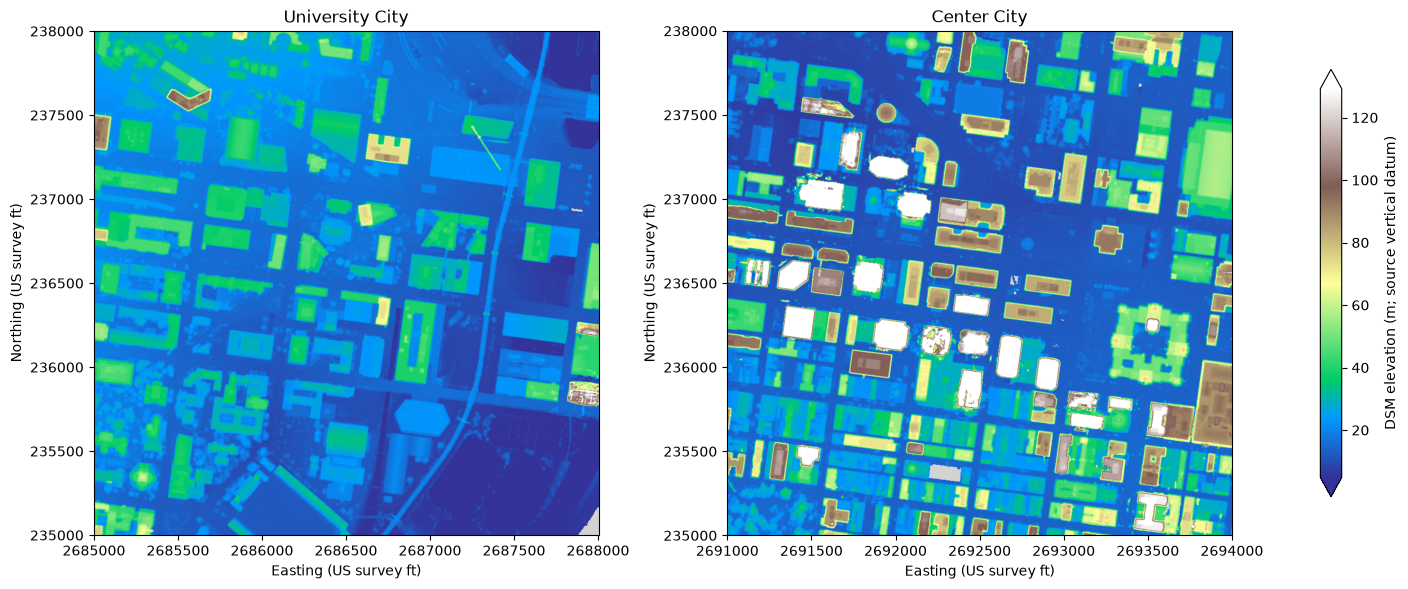

In [10]:
values = np.concatenate([data.compressed() for data, transform in rasters])
vmin, vmax = np.percentile(values, [2, 98])
norm = Normalize(vmin=vmin, vmax=max(vmax, vmin + 1))
cmap = plt.colormaps["terrain"].copy()
cmap.set_bad("lightgray")
fig, axes = plt.subplots(1, 2, figsize=(14, 6), constrained_layout=True)
for ax, case, (data, transform) in zip(axes, cases, rasters):
    show(data, transform=transform, ax=ax, cmap=cmap, norm=norm, adjust=False)
    ax.set(title=case["zone"], xlabel="Easting (US survey ft)", ylabel="Northing (US survey ft)")
    ax.ticklabel_format(style="plain", useOffset=False)
fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=axes,
             label="DSM elevation (m; source vertical datum)", shrink=0.75, extend="both")
fig.savefig(OUT / "center_city_university_city_dsm.png", dpi=160)
plt.show()

## Try it yourself

1. Change `CELL_SIZE_M` to 2 and rerun from Step 4. Compare roof detail and speckle.
2. Compare the raw maximum and smoothed surfaces. Which small features disappear?
3. Why do you need a terrain model to estimate building heights?

**Outputs:** `_max.tif` (raw maximum), `_idw.tif` (raw interpolation), and `_dsm.tif` (smoothed surface), plus pipeline JSONs and comparison figures in `outputs/lidar/case_studies/`. Keep raw and smoothed surfaces separate when measuring heights.
